# NN_L13_context_length

**Test-year mean absolute error of the zero-shot Chronos-2 forecast of Romanian day-ahead prices as a function of the context length (168 to 8,192 hours), against LEAR.**

Neural Networks and Deep Learning (NN), Lecture 13 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L13/NN_L13_context_length/NN_L13_context_length.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Chronos-2 MAE, context 168 h = 24.45   [ctx.168]
Chronos-2 MAE, context 512 h = 21.34   [ctx.512]
Chronos-2 MAE, context 2048 h = 20.72   [ctx.2048]
Chronos-2 MAE, context 8192 h = 20.95   [ctx.8192]


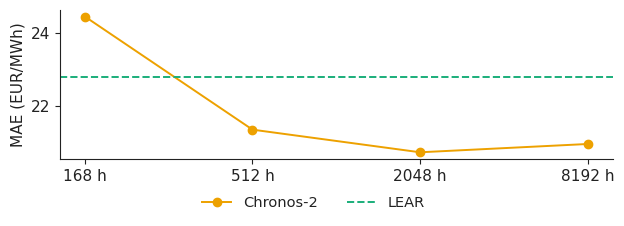

In [3]:
RES = REPO + 'lectures/L13/results/'
F = pd.read_csv(RES + 'forecasts_hourly.csv', parse_dates=['date'])
MODELS = ['naive', 'lear', 'dnn', 'nbeats', 'chronos2', 'chronos2_cov', 'bolt', 'timesfm', 'ens']
C = [168, 512, 2048, 8192]
m = {c: float((F[f'chronos2_ctx{c}'] - F['actual']).abs().mean()) for c in C}
for c in C:
    show(f'ctx.{c}', f'Chronos-2 MAE, context {c} h', round(m[c], 2))
fig, ax = plt.subplots(figsize=(6.4, 2.3))
ax.plot(range(4), [m[c] for c in C], marker='o', color=PAL['alt'], label='Chronos-2')
ax.axhline(float((F['lear'] - F['actual']).abs().mean()), color=PAL['benchmark'], ls='--', label='LEAR')
ax.set_xticks(range(4))
ax.set_xticklabels([f'{c} h' for c in C])
ax.set_ylabel('MAE (EUR/MWh)')
legend_bottom(fig)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig('context_length.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()